# Assignment 2: Exploring sources of bias in data
## Bias in data, demystified

**All datasets have limitations. Any of these limitations can be a potential source of bias.** In the context of data, a "bias" is really just a divergence between what a dataset is supposed to capture about the world--according to the *dataset designer's intention*, or according to the *end-user's expectations*--and what's actually represented in the data. 

So biases in data are often highly *contextual*, which can make them subtle and hard to spot. Similarly, it's hard to predict ahead of time what the *consequences* of those biases might be, because it depends on what the data is being used for.

Nevertheless some sources of "bias" in data show up over and over again. Some of these are:
- **duplicated data:** the same data shows up multiple times
- **incomplete data:** some data is missing from the dataset
- **misleading data:** it looks like a piece of data means one thing, but it actually means something different
- **unrepresentative data:** the dataset doesn't represent the population it's gathered from OR the population it's intended to model


Any of these sources of bias, unless their properly documented (with a data statement, etc) can have unintended consequences: they cause a researcher who is using the data to reach incorrect conclusions, or cause a machine learning model that is trained on that dataset to make classification errors.

The nature or scale of these consequences can be hard to predict. That's why any time you prepare to use data that you didn't gather yourself, it pays to spend some time exploring the dataset, identifying limitations, and thinking critically about how these limitations might affect your analysis or your machine learning model.

## Introduction to Assignment 2
For this assignment, you'll be working with the Wikipedia Talk Corpus. You have already created a data statement for this dataset in class, so you're an 'expert' on it compared to most people!

**In assignment 1, you learned how to process and analyze a dataset created by someone else.** In that assignment, we took the dataset at face value: we assumed that there were no major errors, no missing data, nothing that would skew our results. We assumed that the dataset really did accurately capture all the bike and pedestrian traffic on the Burke-Gilman trail over the specified period of time.

**In assignment 2, we'll also be analyzing a dataset created by someone else,** but this time *we won't assume that the data is complete and correct.* Instead, we will try to identify ways in which the data might be WRONG, and form hypotheses about how the limitations we discover might make it an unsuitable, or at least a potentially problematic, training dataset for a general-purpose hostile speech detector. 

**There are 16 questions in this assignment, across three sections:**

***In part 1 of this assignment,*** you will load one type of Wikipedia Talk Corpus data--the demographics of the crowdworkers who labelled the comments--into your copy of this Jupyter Notebook, and we will walk through a series of data processing steps, with the goal of ending up with a complete and accurate set of data about all of those crowdworkers. In the process, we will discover and discuss several limitations of the dataset.

***In part 2 of this assignment,*** you will generate some basic descriptive statistics about the demographics of the crowdworkers described in that dataset. If you are comfortable in Python, you can perform that analysis in this Notebook. If you aren't as comfortable in Python (yet!), you can perform the analysis in Google Sheets (just be sure to link to that Google Sheet from this notebook, and set the permissions so that your instructors can view it!). 

***In part 3 of this assignment,*** you will answer some additional research questions about this dataset. Some of these questions can be answered without writing additional code or analyzing additional data; other questions will require you to combine this dataset another dataset in the corpus. You will have the option to choose whether you want to answer code or no-code questions.

Whether you choose code or no-code question for part 3, you will need to write your responses to the question within this notebook, and submit a link to this notebook for grading.

Part 3 also contains some optional "challenge" questions that you can investigate if you want to (hint: any one of these challenge questions could be the focus of a final course project).


***Note:*** *Since the purpose of this class is to get you comfortable thinking critically (like a researcher), rather than programming perfectly, you won't be graded on your code. You'll be graded on how well you DOCUMENT YOUR PROCESS and REFLECT on the implications of your findings. If you still aren't sure what that means, ask your instructor or TA!*

## Part 1: Cleaning and analyzing the annotator demographic data

For the first part of this assignment, we're going to prepare one set of Wikipedia Talk data--the annotator demographics files--for analysis. In the process we'll perform a few "sanity checks" to make sure we understand what the data means, and know any limitations.

This sort of "[data wrangling](https://en.wikipedia.org/wiki/Data_wrangling)" is a critical, if sometimes tedious, first step for any quantitative research project.

### 1.1 Load the data into the notebook

According to the documetation, the worker demographic data for the Wikipedia Talk Corpus is spread across three files:
- ``toxicity_worker_demographics.tsv``
- ``aggression_worker_demographics.tsv``
- ``attack_worker_demographics.tsv``

We will need to combine the data in these three files to come up with our canonical list of workers. 
**Just like working with data in the real world, you will need to retrieve the files from their source (Figshare) and transfer them into your notebook server**.

- **Toxicity dataset:** [data](https://figshare.com/articles/dataset/Wikipedia_Talk_Labels_Toxicity/4563973) (Note: this is 35Mb!), [documentation](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Toxicity), [questionnaire shown to crowdworkers](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/toxicity_question.png)
- **Aggression dataset:** [data](https://figshare.com/articles/dataset/Wikipedia_Talk_Labels_Aggression/4267550) (Note: this is 74Mb!), [documentation](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Aggression), [questionnaire shown to crowdworkers](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/aggression_question.png)
- **Personal attacks dataset:** [data](https://figshare.com/articles/dataset/Wikipedia_Talk_Labels_Personal_Attacks/4054689) (this is only 92k), [documentation](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Personal_Attacksv), [questionnaire shown to crowdworkers](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/attack_question.png)

First we'll load each of the annotator datafiles into our Notebook and save them into data structures that's easy to work with. In this case, I'm choosing to save each of these files as a list-of-dictionaries, since that's fairly standard, and it makes it easy to check your work as you go.

By the way: ``.tsv`` stands for "tab-separated values", and it means that this file is organized into rows and columns, like a spreadsheet, and the data values for each column are separated by "tab" characters.

In [3]:
#import the csv module, a little code toolkit for working with spreadsheet-style data files
import csv

The function below will load in a tab-separated (.tsv) file and convert it into a lists-of-dictionaries. 

If you don't have much experience with Python, this (and some of the other code in this notebook) might be hard to understand. That's okay! For now, it's most important that you know what it does.

If you have a ***lot*** of experience with Python, the code in this notebook might seem really, really primitive. That's also okay! Remember: in this course we're primarily interested in data, not code. Code is just one of the many tools we use to ask and answer questions about data.

In [4]:
def prepare_datasets(file_path):
    """ 
    Accepts: path to a tab-separated plaintext file
    Returns: a list containing a dictionary for every row in the file, 
        with the file column headers as keys
    """
    
    with open(file_path) as infile:
        reader = csv.DictReader(infile, delimiter='\t')
        list_of_dicts = [dict(r) for r in reader]
        
    return list_of_dicts

### 1.2 Identifying duplicated datafiles
Let's load our three .tsv files into Python and store them as three variables with relevant names, so that we know which is which. 

Once we've created these three lists-of-dicts, we will do two things to check our work so far: 
- we will print the first annotator's demographic data (list index ``[0]``) so that we know what the format looks like
- we will print the length of each list (the ``len`` function), to see how many rows is in each file. Each row should correspond to one crowdworker/annotator.

***Note:*** for the cell below to run, your version of these datafiles and folders will need have the same names as the ones below, and your version of this Notebook will need to be stored in the same directory as the three folders that hold the datafiles.

In [5]:
#load the data from the flat files into three lists-of-dictionaries
toxicity_annotators = prepare_datasets("wikipedia_datasets/toxicity_worker_demographics.tsv")
print(toxicity_annotators[0])
print(len(toxicity_annotators))

attack_annotators = prepare_datasets("wikipedia_datasets/attack_worker_demographics.tsv")
print(attack_annotators[0])
print(len(attack_annotators))

aggression_annotators = prepare_datasets("wikipedia_datasets/aggression_worker_demographics.tsv")
print(aggression_annotators[0])
print(len(aggression_annotators))



{'worker_id': '85', 'gender': 'female', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors'}
3591
{'worker_id': '833', 'gender': 'female', 'english_first_language': '0', 'age_group': '45-60', 'education': 'bachelors'}
2190
{'worker_id': '833', 'gender': 'female', 'english_first_language': '0', 'age_group': '45-60', 'education': 'bachelors'}
2190


Interesting! This tells us a few things that we didn't know before:
1. it looks like the demographic data matches what's listed in [the schema](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Schema_for_{attack/aggression/toxicity}_worker_demographics.tsv), which is great!
2. it looks like the "toxicity" dataset was annotated by a lot more people (3,591) than the "attack" or "aggression" datasets (2,190)
3. ``aggression_worker_demographics.tsv`` and ``attack_worker_demographics.tsv`` seem to contain the same number of workers, and the worker at the beginning of each list has the same ID and demographic data.

Let's dig a little deeper into finding #3. Are the ***last*** entries in both of these lists also identical?

In [6]:
print(attack_annotators[-1]) # "-1" tells Python to find the last item in any list
print(aggression_annotators[-1])


{'worker_id': '3876', 'gender': 'female', 'english_first_language': '1', 'age_group': '30-45', 'education': 'bachelors'}
{'worker_id': '3876', 'gender': 'female', 'english_first_language': '1', 'age_group': '30-45', 'education': 'bachelors'}


Yes, the last rows in these two lists are also identical! 

And in fact if you had opened the two lists in a text editor or spreadsheet program, you would find that the *aggression and attack .tsv files contain exactly the same data.* By the way, it doesn't say anywhere in the dataset documentation that these two files are identical!

That brings us to our first lesson about bias: watch out for duplicate data! 

Consider: *What would have happened if we had just combined these three files and then analyzed the worker demographics? What mistaken conclusions might we have drawn from that?*
 
Fortunately, now that we know that there is duplicate data we can work around it. Since two files are identical, we only need to use one of them. So from now on, we will ignore ``aggression_annotators`` entirely. 

Since want to remember that ``attack_annotators`` really refers to both "attack" and "aggression" annotators, we can just rename the variable we're using to store that dataset.

In [7]:
attack_aggro_annotators = attack_annotators

Okay, that looks good. Now we can continue getting our data ready for analysis--while keeping an eye out for additional duplicate data and other "gotchas"!

### 1.3 Understanding what the properties of your data really mean

Whenever you are working with data that you didn't create, it's very useful to perform some basic sanity-checking to make sure the data actually means what you think it means. 

For example, take the ``worker_id`` field in our datasets. 

The [schema](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Schema_for_{attack/aggression/toxicity}_worker_demographics.tsv) says that the ``worker_id`` field contains an "anonymized crowd-worker id" and that this ID is meant to join the worker demographics datafiles with the annotator comments datafiles, so that if we wanted find all of the comments that worker "85" (from above) labelled, we could find her by looking for that ID in each row of ``toxicity_annotated_comments.tsv``.

So far, so good. But since we want to combine the toxicity and attack + aggression annotator demographics data into a single dataset, we probably want to know...

1. did any of the values for ``worker_id`` appear in both datasets?
2. if so, do they correspond to the same person (or at least, a person with matching gender, age group, etc.)?

### 1.4 Checking for duplicate worker IDs

If we want to see if worker_id means the same thing across datasets, the first step is to see if any of the same worker_ids exist across the two datasets.

To check this, let's first pull all the worker IDs out of each dataset and combine them into a single list. Then we can check that list to see if it contains any duplicate values. If it does, we know that there is at least 1 value for ``worker_id`` that appears in both datasets.

**Note:** *We're assuming that there are no duplicate values for ``worker_id`` within each dataset. (There aren't, I checked). It's a pretty safe assumption though, because worker_id is intended to be a unique key that links the ``worker_demographics.tsv`` files and the ``annotated_comments.tsv`` datasets. Can you explain why it would be an issue if there were duplicate values for ``worker_id`` within an individual dataset?*

In [8]:
#pull the worker ids out of the individual files
tox_w_ids = [item['worker_id'] for item in toxicity_annotators]
aa_w_ids = [item['worker_id'] for item in attack_aggro_annotators]


#create a new list to hold all the ids
all_w_ids = tox_w_ids + aa_w_ids

# #combine the two worker_id lists into the new list
# all_w_ids.extend(tox_w_ids)
# all_w_ids.extend(aa_w_ids)

In [9]:
#how many worker ids do we have, total? 
#this number should match the total count of toxicity_annotators and attack_aggro_annotators (3591 + 2190 = 5781)
print(len(all_w_ids))

5781


In [10]:
#what does our new list look like? Let's print the first five values
print(all_w_ids[0:5])

['85', '1617', '1394', '311', '1980']


Below is our duplicate-checker function. You pass it a list of values, and it will return "True" if it finds at least 1 duplicate value in that list. Can you figure out how it works?

In [11]:
def determine_dupes(w_ids):
    set_of_ids = set()
    
    found_a_dupe = False
    
    for w in w_ids:
        if w in set_of_ids:
            found_a_dupe = True
        else:
            set_of_ids.add(w)

    return found_a_dupe

In [12]:
#we'll call determine_dupes to check for duplicates in the combined worker id list
has_dupes = determine_dupes(all_w_ids)

#if this prints 'True', that means we found at least one duplicate ID
print(has_dupes)

True


Hmmm... So it looks like there's at least 1 duplicate! Okay, we'll need to do some additional verification before we can decide what to do with that information. 

The next thing we'll do is check how many duplicates there are. We'll write a short script that reads through ``all_w_ids`` and every time it finds a value that appears more than once, it adds that value to a new list.

Can you figure out how the script below works?

In [13]:
#create an empty list to hold any duplicate worker_id values we find
dupes = []

#look through the data, if you encounter any value more than once, add it to our 'dupes' list
for w in all_w_ids:
    if all_w_ids.count(w) > 1:
        dupes.append(w)

#how many values were added to 'dupes'?        
print(len(dupes))

#how many worker_ids are present twice in the dataset?
#can you explain why we are dividing the length of "dupes" by 2 in order to answer that question?
print(len(dupes)/2)

3716
1858.0


Huh, so it looks like 1,858 of the ``worker_ids`` in our merged dataset are duplicates! That's a lot of duplication, since our list was only 5,781 rows in the first place, including these dupes! 

We will definitely need to account for these duplicates before we start analyzing worker demographics. 
- If the duplicate ``worker_id``s have different demographic metadata, we will assume they are different people with the same ID. 
- If the metadata is identical, then we know we can safely remove the duplicates
- If some metadata is identical and some is different... well, let's hope that's not the case!

### 1.5 Check for duplicate worker demographic metadata
Let's see if it's just the value for ``worker_id`` that is duplicated across the two datasets (meaning that the these duplicate ids correspond to different workers with different demographics), or if ``worker_id`` really corresponds to the same people across ``toxicity_annotators`` and ``attack_annotators``.

To do this we'll perform some spot checks, meaning we'll visually compare the demographic data of workers with duplicate IDs, to see if they look like the same worker, or not. Running random 'spot checks' is a really common and useful way of finding systematic issues with your data without having to check every entry. 
 

First, we'll extract 10 random ids from our dupe set. Using a random sample (rather than just looking at the first 10 rows, for instance) helps us be more confident that any patterns we see are really there.

In [14]:
#handy Python library that lets you select things randomly from a list
import random

In [15]:
#convert our 'dupes' list into a set
#bonus: can you explain why we created "dupeset" rather than just grabbing 10 random values from "dupes"?
#hint: in Python, a 'set' is like a list that can only contain a single instance of any value
dupeset = sorted(set(dupes))

#store our random sample of dupes in its own list
dupe_sample = random.sample(list(dupeset), 10)

#print to confirm everything looks how we expect it to...
print(dupe_sample)

['5', '2483', '98', '2826', '3273', '3677', '1420', '261', '2273', '2438']


Now, we'll use this ``dupe_sample`` list that we created to pull the corresponding worker demographics from each of our two datasets, using the function below. See if you can figure out how the function works!

In [16]:
def worker_id_lookup(annotator_list, dupe_id):
    """
    Accepts: a list of dictionaries 
        & a list of known duplicate values for
        the key 'worker_id' in those dictionaries
    
    If a duplicate value for worker_id is found, 
        print the complete dictionary of demographic data for that worker
    
    """
    
    for a in annotator_list:
        if a['worker_id'] == dupe_id:
            print(a)
            
#loop through the duplicate sample list and call our worker_id_lookup function
#to check each dataset for corresponding worker demographic data
for d in dupe_sample:
    worker_id_lookup(toxicity_annotators, d)
    worker_id_lookup(attack_aggro_annotators, d)

{'worker_id': '5', 'gender': 'male', 'english_first_language': '0', 'age_group': '18-30', 'education': 'professional'}
{'worker_id': '5', 'gender': 'male', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors'}
{'worker_id': '2483', 'gender': 'male', 'english_first_language': '0', 'age_group': '30-45', 'education': 'hs'}
{'worker_id': '2483', 'gender': 'female', 'english_first_language': '0', 'age_group': 'Over 60', 'education': 'hs'}
{'worker_id': '98', 'gender': 'female', 'english_first_language': '0', 'age_group': '30-45', 'education': 'hs'}
{'worker_id': '98', 'gender': 'male', 'english_first_language': '0', 'age_group': '18-30', 'education': 'hs'}
{'worker_id': '2826', 'gender': 'male', 'english_first_language': '0', 'age_group': '18-30', 'education': 'professional'}
{'worker_id': '2826', 'gender': 'female', 'english_first_language': '0', 'age_group': '45-60', 'education': 'bachelors'}
{'worker_id': '3273', 'gender': 'male', 'english_first_language': '0', '

Aha! It looks like few if any of these ``worker_id`` values correspond to the same demographic data info across the two datasets. 

It's possible that some of the same people labelled both datasets and were assigned different IDs each time. But there's no way for us to determine that with the data we have. 

So for now we will assume that these datasets were labelled by two entirely different sets of crowdworkers. Which means we can combine these two datasets into one, with no duplication to mess up our analysis.

### 1.6 Final preparation of the dataset

Before we start our analysis of worker demographics, let's do two more things:

1. Since we know now that worker ID isn't unique, let's give each worker in our new, combined dataset a **truly** unique ID.
2. While we're at it, let's also add a new field to each worker's demographic dictionary that lists which dataset the worker worked on (toxicity or attack/aggressive).

In [17]:
def add_dataset_id(list_of_dicts, dataset_ref):
    """
    Accepts: a list of dictionaries & a strig value for "dataset"
    Returns: that list of dictionaries, with the new "dataset" key and the specified value
    """
        
    for w in list_of_dicts:
        w.update({"dataset" : dataset_ref})
        
    return list_of_dicts

In [18]:
#update our worker demographic datasets with the new key and value
toxicity_annotators = add_dataset_id(toxicity_annotators, "toxicity")
attack_aggro_annotators = add_dataset_id(attack_aggro_annotators, "attack and aggression")

In [19]:
#did it work?
print(toxicity_annotators[0])
print(attack_aggro_annotators[0])

{'worker_id': '85', 'gender': 'female', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors', 'dataset': 'toxicity'}
{'worker_id': '833', 'gender': 'female', 'english_first_language': '0', 'age_group': '45-60', 'education': 'bachelors', 'dataset': 'attack and aggression'}


Great. Now we'll use the function below to... 

1. combine the two datasets into one
2. assign a truly unique id to each worker 

It doesn't matter what this ID is, as long as its unique within the dataset. We'll use sequential IDs, starting at "1" and going up from there.

In [20]:
def finalize_dataset(list1, list2):
    
    #combine the two lists into a new one
    combined_list = list1 + list2
    
    #initialize our counter variable
    new_id = 1
    
    for w in combined_list:
        #add the new sequential id field, and populate with the current value of 'counter'
        w.update({"unique_id" : str(new_id)})
        
        #increment the counter variable by 1, so that the next ID will be one number higher
        new_id = new_id + 1
        
    return combined_list

In [21]:
#create our new combined list with sequential IDs
all_annotators = finalize_dataset(toxicity_annotators, attack_aggro_annotators)

#print the list length and a sample, for sanity-checking purposes
print(len(all_annotators))
print(all_annotators[0])

5781
{'worker_id': '85', 'gender': 'female', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors', 'dataset': 'toxicity', 'unique_id': '1'}


It worked! Now we can FINALLY start to analyze this dataset, and find out more about the workers who labelled the Wikipedia Talk Corpus.

## Part 2: Analyzing worker demographics

Now that we have our worker demographic data de-duplicated, combined and uniquely identified, we can start using it to ask and answer research questions! 

You are welcome to do this next steps in Python, here in this notebook. But if you aren't super comfortable with Python, you can run the cell below to export this dataset to a .csv file called ``a2_all_annotator_demographics.csv`` which you can open in Google Sheets and do the analysis there.

Note: if you choose Google Sheets, please title your Google Sheet "A2 worker demographics", share it with your instructor and TA ("can view" or "can edit") and paste a link to it in a Markdown cell below.

In [22]:
with open('a2_all_annotator_demographics.csv', 'w', encoding='utf-8') as f:
    writer = csv.writer(f)
    #write a header row
    writer.writerow(('unique_id',
                     'worker_id', 
                     'gender', 
                     'english_first_language', 
                     'age_group',
                     'education',
                     'dataset',))
    #loop through our dataset and write it to the file, row by row
    for a in all_annotators:
        writer.writerow((a['unique_id'], a['worker_id'], a['gender'], a['english_first_language'], a['age_group'], a['education'], a['dataset']))

### 2.1 Questions 1-4: compute descriptive statistics

Please create tables or bar charts that answer the following questions:

- **Q1.** What is the gender distribution of these workers?
- **Q2.** What is the distribution of the workers by first language?
- **Q3.** What is the distribution of these workers by age group?
- **Q4.** what is the distribution of these workers by education level?

If you *do not know* how to create tables in Python, you can use Excel or another tool and upload it to your notebook server. However I would encourage you to try out the [Pandas](https://pandas.pydata.org/pandas-docs/version/0.15/10min.html) library, which makes it very easy to convert your data into tidy tabular representations. If you do not know how to create charts in Python, you can use an easy library such as [Plotly](https://plotly.com/python/v3/statistics-charts/#new-to-plotly) to create charts.

**POST YOUR ANSWERS TO QUESTIONS 1-4 HERE.**

Use both Markdown and code-formatted cells.

,gender,count,percent
0,male,3676,63.6
1,female,2103,36.4
2,other,2,0.0


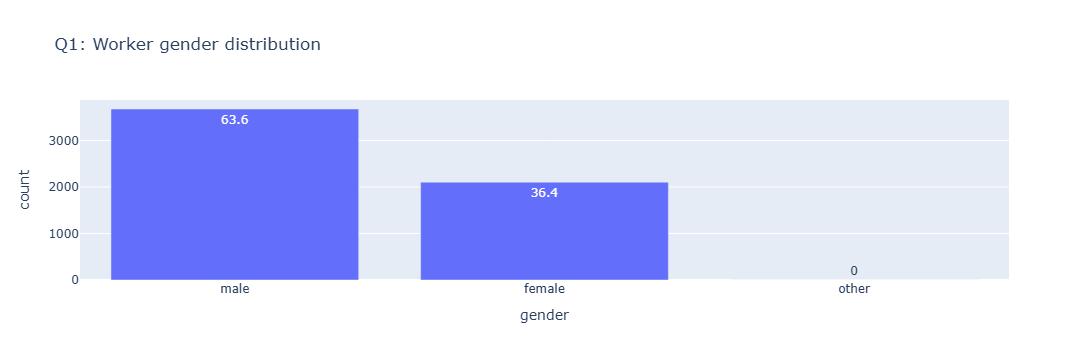

In [23]:
import pandas as pd
import plotly.express as px

# Turn our list-of-dictionaries into a DataFrame
df = pd.DataFrame(all_annotators)

# csv.DictReader stores blank cells as empty strings, so label them "missing"
# so they show up in the counts instead of disappearing
df = df.replace("", "missing")

# The first-language column is coded 0/1, so make it readable
df["english_first_language"] = df["english_first_language"].replace(
    {"1": "English is first language", "0": "English is not first language"}
)

def summarize(column, title):
    """Show a count + percent table and a bar chart for one column."""
    counts = df[column].value_counts().rename_axis(column).reset_index(name="count")
    counts["percent"] = (counts["count"] / len(df) * 100).round(1)
    display(counts)
    px.bar(counts, x=column, y="count", text="percent", title=title).show()

# Q1: gender
summarize("gender", "Q1: Worker gender distribution")

,english_first_language,count,percent
0,English is not first language,4713,81.5
1,English is first language,1068,18.5


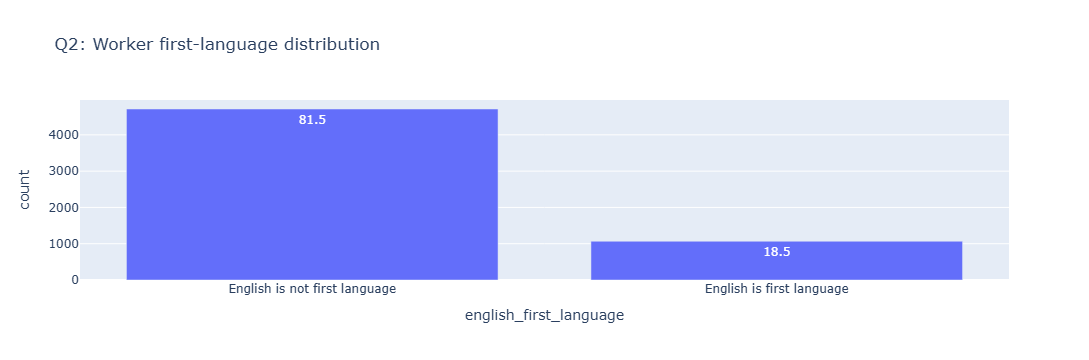

In [24]:
# Q2: first language
summarize("english_first_language", "Q2: Worker first-language distribution")

,age_group,count,percent
0,18-30,2911,50.4
1,30-45,2078,35.9
2,45-60,514,8.9
3,Under 18,116,2.0
4,missing,112,1.9
5,Over 60,50,0.9


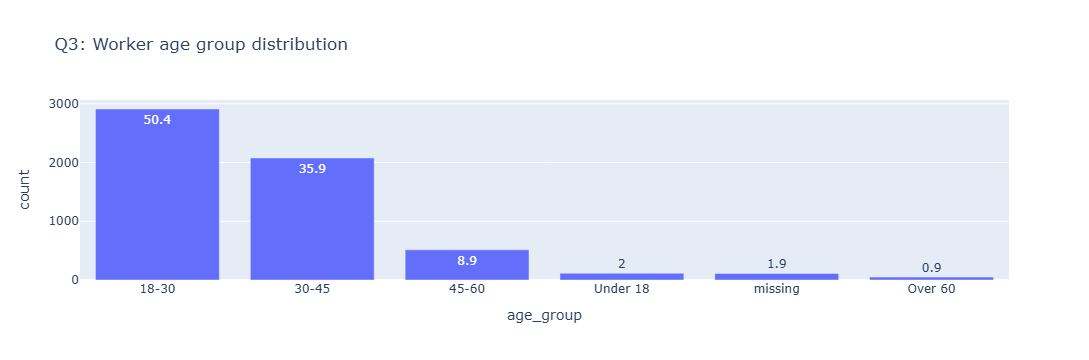

In [25]:
# Q3: age group
summarize("age_group", "Q3: Worker age group distribution")

,education,count,percent
0,bachelors,2303,39.8
1,hs,1657,28.7
2,masters,931,16.1
3,professional,684,11.8
4,some,141,2.4
5,doctorate,61,1.1
6,none,4,0.1


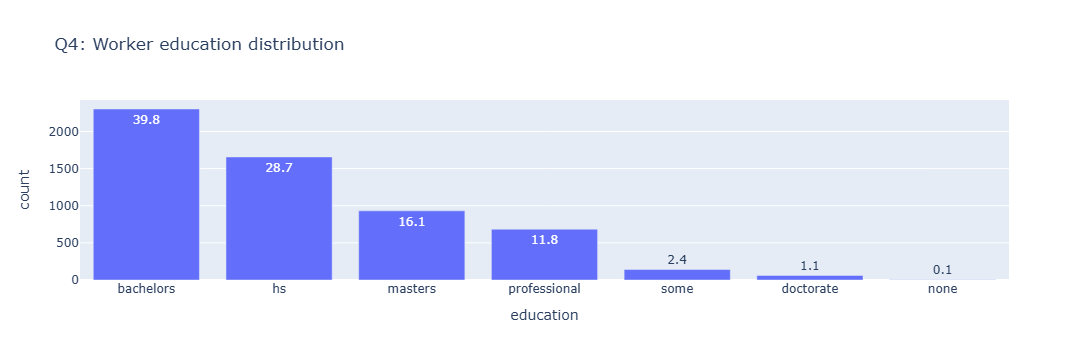

In [26]:
# Q4: education level
summarize("education", "Q4: Worker education distribution")

### 2.2 Questions 5-8

Each of the next four questions requires a different kinds of answer.

Questions 5 and 6 have a "correct" answer, but we'll still give you credit for the "incorrect" answer as long as you document your process well (in Markdown, in this notebook). These questions are intended to get you thinking about how even small errors in data processing can create bias in your data.

Question 6 requires you to re-run some (but not all) of the data processing steps you performed above. Do this by copying the code into NEW cells below this line, and make sure to document each step using Markdown cells or inline (#) comments. You will probably want to change the names of the variables too.

- **Q5.** Analyze all_annotators in Sheets or Jupyter: Do any of the fields in this dataset have missing data? If so, which fields, and what % of the rows contain missing values?
- **Q6.** Build a version of the all_annotators dataset *without removing duplicates*, then re-run the summary statistics from questions 1-4. How have these summary statistics changed?

Questions 7 and 8 don't have one "correct" answer. These questions are intended to get you thinking about how using this dataset to train a machine learning model might lead to bias in the way that model performs when used as intended. You will need to provide a written answer to each of these questions in 3-4 full sentences. Consider what you know about the workers themselves, the task they were given, and about the purpose of the Perspective API.

Question 7 requires you to do some research of your own (hint: use Google). Question 8 doesn't require any new analysis or research, just critical thinking.

- **Q7.** In general, how do the demographics of these workers compare to those of English-speaking internet users overall? Why would it matter if the worker demographics don't match the demographics of the intended end users of the Perspective API?

- **Q8.** Given what you now know about the Wikipedia Talk Corpus, what issues might arise if it was used to train a machine learning-driven "hostile speech detector" that could be used on any website or social media platform?


**POST YOUR ANSWERS TO QUESTIONS 5-8 HERE.**

Use both Markdown and code-formatted cells.

In [27]:
import pandas as pd

# Fresh DataFrame from the original data (blank cells are empty strings)
df_raw = pd.DataFrame(all_annotators)
df_raw = df_raw.replace("", pd.NA)   # treat blanks as missing

missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(2)
})
display(missing)

,missing_count,missing_percent
worker_id,0,0.00
gender,0,0.00
english_first_language,0,0.00
age_group,112,1.94
education,0,0.00
dataset,0,0.00
unique_id,0,0.00


**Q5:**
Only one field in all_annotators has missing data: age_group. It is blank for 112 of the 5,781 rows, or 1.94%. The other six fields (worker_id, gender, english_first_language, education, dataset, unique_id) have 0% missing. The share is small, but it isn’t random noise: we don’t know why those 112 workers didn’t report an age. Any age-based analysis has to either drop them or label them “missing”, and I kept them as their own category so the totals still add up to 5,781.

7971


,clean_%,with_dupes_%,change (pts)
gender,,,
male,63.6,63.0,-0.6
female,36.4,36.9,0.5
other,0.0,0.0,0.0


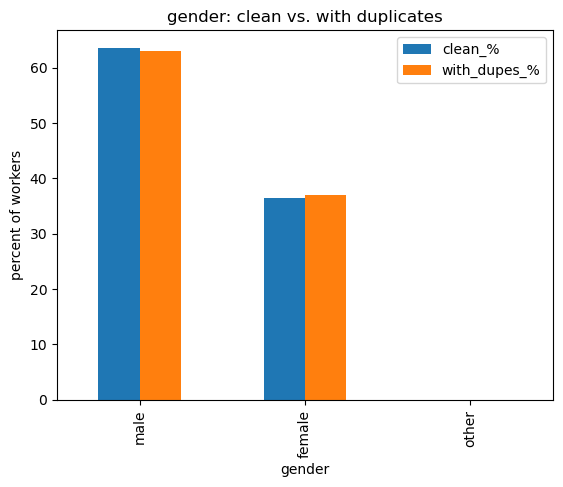

,clean_%,with_dupes_%,change (pts)
english_first_language,,,
English is not first language,81.5,81.6,0.1
English is first language,18.5,18.4,-0.1


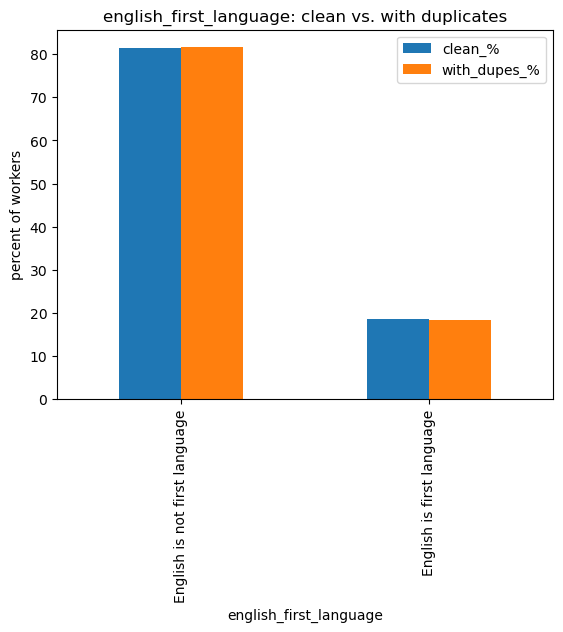

,clean_%,with_dupes_%,change (pts)
age_group,,,
18-30,50.4,49.7,-0.7
30-45,35.9,36.5,0.6
45-60,8.9,9.2,0.3
Under 18,2.0,1.9,-0.1
missing,1.9,1.8,-0.1
Over 60,0.9,0.9,0.0


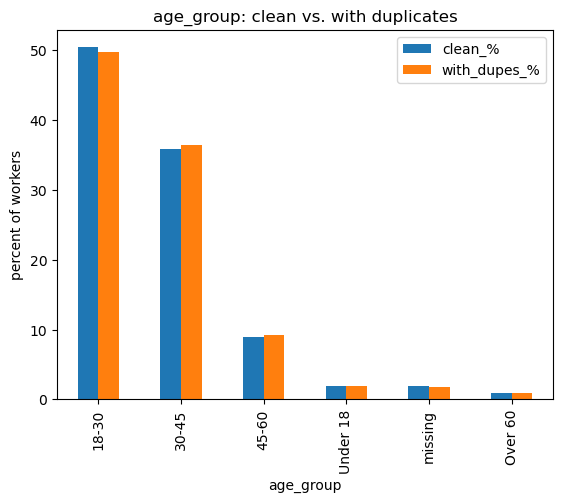

,clean_%,with_dupes_%,change (pts)
education,,,
bachelors,39.8,39.7,-0.1
hs,28.7,28.7,0.0
masters,16.1,16.5,0.4
professional,11.8,11.6,-0.2
some,2.4,2.4,0.0
doctorate,1.1,1.0,-0.1
none,0.1,0.1,0.0


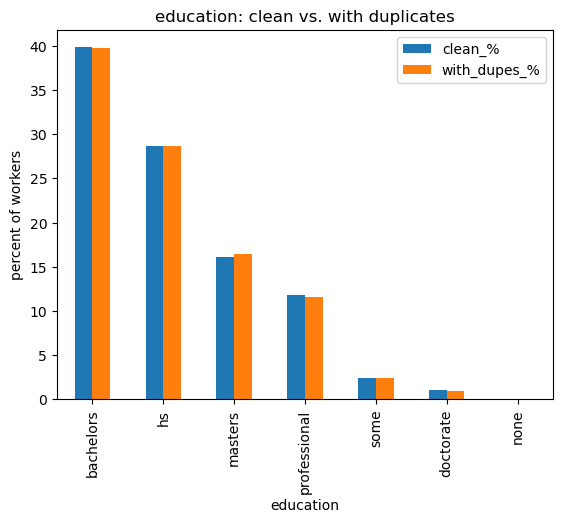

In [28]:
import matplotlib.pyplot as plt

# Reload the three files so we start clean
tox_raw    = prepare_datasets("wikipedia_datasets/toxicity_worker_demographics.tsv")
attack_raw = prepare_datasets("wikipedia_datasets/attack_worker_demographics.tsv")
aggr_raw   = prepare_datasets("wikipedia_datasets/aggression_worker_demographics.tsv")

# Combine all three WITHOUT removing the duplicate file
all_with_dupes = tox_raw + attack_raw + aggr_raw
print(len(all_with_dupes))   # should be 7971

df_dupes = pd.DataFrame(all_with_dupes).replace("", "missing")
df_dupes["english_first_language"] = df_dupes["english_first_language"].replace(
    {"1": "English is first language", "0": "English is not first language"})

# The cleaned version from 2.1 (rename if your variable differs)
df_clean = pd.DataFrame(all_annotators).replace("", "missing")
df_clean["english_first_language"] = df_clean["english_first_language"].replace(
    {"1": "English is first language", "0": "English is not first language"})

def compare(column):
    clean = df_clean[column].value_counts(normalize=True).mul(100).round(1)
    dupes = df_dupes[column].value_counts(normalize=True).mul(100).round(1)
    out = pd.DataFrame({"clean_%": clean, "with_dupes_%": dupes})
    out["change (pts)"] = (out["with_dupes_%"] - out["clean_%"]).round(1)
    display(out)
    out[["clean_%", "with_dupes_%"]].plot.bar(title=f"{column}: clean vs. with duplicates")
    plt.ylabel("percent of workers")
    plt.show()

for col in ["gender", "english_first_language", "age_group", "education"]:
    compare(col)

**Q6:**
Process: I reloaded the toxicity, attack, and aggression files and combined all three without removing the duplicate file. The attack and aggression files are identical, so that gave 7,971 rows (3,591 + 2,190 + 2,190) instead of 5,781. I then re-ran the Q1-Q4 summaries on both versions and compared the percentages.

Findings: The percentages barely moved:

Gender: male dropped from 63.6% to 63.0% (−0.6 pts) and female rose from 36.4% to 36.9% (+0.5 pts). “Other” stayed at about 0%.
First language: “English is not first language” went from 81.5% to 81.6% (+0.1) and “English is first language” from 18.5% to 18.4% (−0.1).
Age group: The 18-30 group dropped from 50.4% to 49.7% (−0.7 pts), the largest age shift. The 30-45 group rose from 35.9% to 36.5% (+0.6) and 45-60 from 8.9% to 9.2% (+0.3). The other groups (under 18, over 60, missing) moved by 0.1 points or less.
Education: The largest shift was masters, which rose from 16.1% to 16.5% (+0.4). Professional fell from 11.8% to 11.6% (−0.2), and bachelors, high school, some college, doctorate, and none each moved by 0.1 points or less.

**Q7:**
The crowdworkers who labeled this dataset skew male (63.6% male vs. 36.4% female), young (about 86% were aged 18-45, including 50.4% aged 18-30, while only 0.9% were over 60), and mostly non-native English speakers (81.5%), even though they were judging English-language comments. For comparison, Pew Research Center reports that 90% of U.S. adults aged 65 and older used the internet in 2025, suggesting that older adults are widely online even though they are almost absent from the pool of crowdworkers. (This is a rough comparison, since Pew’s cutoff is 65+ and covers only U.S. adults.) This matters because toxicity is subjective, and who labels the data shapes what the model learns to call hostile. Non-native speakers may misread sarcasm, idioms, or dialect, and a young, male-skewed group may be more or less sensitive to certain insults than the broader population. If the Perspective API is meant to serve all English-speaking internet users but learns from this narrow group, it will reflect the labelers’ judgments and could misclassify speech from groups who were barely represented, such as older adults.

**Q8:**
The Wikipedia Talk Corpus comes from one community, Wikipedia editors debating article edits, whose tone and vocabulary differ a lot from Twitter, Reddit, or gaming chat. A detector trained on it could miss platform-specific slang and insults, or flag ordinary speech as "hostile" or "harmful". The labelers add to this problem: they were mostly young, male, and non-native English speakers, so their sense of “toxic” may not match that of the people actually using these platforms. The model could also learn shortcuts, such as treating identity terms or certain dialects as signs of toxicity if those appear mostly in comments labeled toxic. Finally, the undocumented duplicate file and the reused worker IDs show that the dataset’s documentation has gaps, so other problems may be hidden, and a model trained on it could be trusted more than it deserves.

## Part 3: Digging deeper

### 3.1 Questions 9-16

Below is a list of additional questions that you should be able to answer, based on what you've done today. 

***You may answer EITHER the "code" questions (Q9-Q12) OR the "no code" questions (Q13-Q16).***

If you don't feel very comfortable with Python yet, choose the "no code" questions.

- ***For the "code" questions*** you will need to load ``toxicity_annotations.tsv`` into Python and join that dataset with ``all_annotators`` on ``worker_id``.
- ***For the "no code" questions*** you will need to load the file ``toxicity_labelled_comments_3k_sample.csv`` into Google Sheets. This file contains the text of 3000 comments that were annotated for toxicity, as well as the toxicity score that each worker gave to these comments. The file is a random sample taken from the ~1.5 million comments contained in ``toxicity_annotated_comments.tsv``

*Note:* answering question 13-16 below ***will require reading some comments that contain offensive speech!*** If you do not want to be exposed to offensive speech, either answer the "code" questions instead, or reach out to your Instructor or TA and ask for an alternate activity.

#### Code questions
- **Q9.** What % of *workers* who labelled the toxicity dataset do we have demographic data for?
- **Q10.** What % of the *comments* in the toxicity dataset were labelled by male vs. female-identified workers?
- **Q11.** What % of the *comments* in the toxicity dataset were labelled by people for whom English is NOT their first language?
- **Q12.** Based on your findings from questions 9-11, how might this dataset present a biased view of "toxicity"? How would you expect such biases to impact how the Perspective API performs? 

#### No-code questions

Before you answer the questions below, read through at least 20 comments from ``toxicity_labelled_comments_3k_sample.csv`` that were labelled "toxic" (-1 or -2), 20 that were labelled "non-toxic" (1 or 2), and 20 that are labelled "neutral" (0). Note in your spreadsheet whether you agree or disagree with the labeller's judgement. 


- **Q13.** Pick 2-3 examples of comments where you disagreed with the labeller about the toxicity of a comment. Why did you disagree? Why do you think that the labeller might have labelled these comments the way they did?
- **Q14.** Pick 2-3 examples of comments where you don't understand what the commenter was saying, and therefore had a hard time classifying as toxic or non-toxic. What additional context or information would you need in order to be confident in your judgement about the toxicity of this comment?
- **Q15.** Read through the [instructions and labelling options](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/toxicity_question.png) given to the crowdworkers. How could the way these instructions were written have made it difficult for crowdworkers to accurately label comments as toxic or non-toxic? If you were going to run a labelling campaign like this one yourself, how would you change these instructions or labelling options to help the crowdworkers make more accurate or consistent judgements about toxicity?
- **Q16.** Based on your findings from questions 13-15, how might this dataset present a biased view of "toxicity"? How would you expect such biases to impact how the Perspective API performs as a general-purpose hostile speech detector? 

**POST YOUR ANSWERS TO QUESTIONS 9-16 HERE.**

Use both Markdown and code-formatted cells.

In [35]:
import os
print(os.listdir("wikipedia_datasets"))

['toxicity_worker_demographics.tsv', 'aggression_worker_demographics.tsv', 'attack_worker_demographics.tsv', 'toxicity_annotations.tsv', '.ipynb_checkpoints']


In [36]:
import pandas as pd

# One row per (comment, worker) label
ann = pd.read_csv("wikipedia_datasets/toxicity_annotations.tsv",
                  sep="\t", dtype={"worker_id": str})
print(ann.shape)
print(ann.head())   # check the column names, you need "worker_id"

# Demographics for toxicity workers ONLY (avoids the reused-ID problem)
tox_demo = pd.DataFrame([w for w in all_annotators if w["dataset"] == "toxicity"])

# ---------- Q9: do we have demographics for the workers who labeled? ----------
labelers = set(ann["worker_id"].unique())
known = set(tox_demo["worker_id"])
matched = labelers & known
print("Workers who labeled:", len(labelers))
print("Workers with demographics:", len(matched))
print(f"Q9: {len(matched) / len(labelers) * 100:.1f}% of workers have demographic data")

# ---------- Join the demographics onto every label ----------
merged = ann.merge(tox_demo, on="worker_id", how="left")
print("Rows before/after merge:", len(ann), len(merged))   # should be equal

# ---------- Q10: gender of the labelers ----------
print("\nQ10: share of labels by gender")
print((merged["gender"].value_counts(dropna=False, normalize=True) * 100).round(1))

# ---------- Q11: English as first language ----------
merged["english_first_language"] = merged["english_first_language"].replace(
    {"1": "English is first language", "0": "English is not first language"})
print("\nQ11: share of labels by first language")
print((merged["english_first_language"].value_counts(dropna=False, normalize=True) * 100).round(1))

(1598289, 4)
   rev_id worker_id  toxicity  toxicity_score
0  2232.0       723         0             0.0
1  2232.0      4000         0             0.0
2  2232.0      3989         0             1.0
3  2232.0      3341         0             0.0
4  2232.0      1574         0             1.0
Workers who labeled: 4301
Workers with demographics: 3591
Q9: 83.5% of workers have demographic data
Rows before/after merge: 1598289 1598289

Q10: share of labels by gender
gender
male      55.6
female    28.6
NaN       15.7
other      0.0
Name: proportion, dtype: float64

Q11: share of labels by first language
english_first_language
English is not first language    69.6
NaN                              15.7
English is first language        14.6
Name: proportion, dtype: float64


**Q9:** 
We have demographic data for 83.5% of the workers who labeled the toxicity dataset (3,591 of 4,301). That leaves 710 workers (16.5%) with no demographic information.

**Q10:** 
Of all labels, 55.6% came from male workers, 28.6% from female workers, and about 0% from workers listed as “other.” The remaining 15.7% came from workers with no demographic data. Among labels where gender is known, the split is about 66% male and 34% female. I got that by dividing each share by 84.3%, the part of the data that has demographics.

**Q11:** 
69.6% of labels came from workers for whom English is not a first language, and 14.6% came from native English speakers. Again, 15.7% are unknown. Among labels with known language, about 83% were from non-native speakers and 17% from native speakers.

**Q12:**
The demographic data is only available for 83.5% of the workers who labeled the toxicity dataset, meaning we don’t know much about the workers who contributed 15.7% of all labels. This makes it harder to know how well the data represents the entire group of labelers. Among the workers we have information on, about 66% were male and 83% did not speak English as their first language, even though they were judging English Wikipedia discussions. Since toxicity can be subjective, the dataset may reflect the opinions and experiences of this specific group rather than a wider range of people. For example, some workers might misunderstand certain phrases, sarcasm, or idioms, or have different ideas about what counts as offensive. Because women and native English speakers were less represented, I would expect the Perspective API to sometimes misjudge language in ways that do not match how these groups understand or experience harmful speech.

In [37]:
import pandas as pd
c = pd.read_csv("toxicity_labelled_comments_3k_sample.csv")
print(c.columns.tolist())   # check the real column names first
print(c.head())

['rev_id', 'worker_id', 'toxicity', 'toxicity_score', 'comment', 'year', 'logged_in', 'ns', 'sample', 'split']
        rev_id  worker_id  toxicity  toxicity_score  \
0  182449647.0       1607         0             0.0   
1  476867038.0       2517         0             0.0   
2  295696781.0       1044         1            -1.0   
3  141509046.0       3284         0             0.0   
4  647794807.0       1014         0             0.0   

                                             comment  year  logged_in  \
0   Try The Name of the Rose first, I think it's ...  2008       True   
1  NEWLINE_TOKENNEWLINE_TOKENIronically, it's kin...  2012      False   
2  NEWLINE_TOKEN:Whew.. ) I would never normally ...  2009       True   
3                            (song)|He Said She Said  2007       True   
4  `NEWLINE_TOKENNEWLINE_TOKEN:Hi. I know you mea...  2015       True   

        ns   sample  split  
0     user   random   test  
1  article  blocked  train  
2     user   random  train  
3  

In [38]:
# Replace "toxicity_score" and "comment" with your actual column names
print(c[c["toxicity_score"] <= -1].sample(10, random_state=1)["comment"].tolist())

['NEWLINE_TOKENNEWLINE_TOKEN== Alleged? ==NEWLINE_TOKENNEWLINE_TOKENHow can you lie and use a word alleged when the conviction & suspensions is online in several v verifable sources. AKC, Pet Abuse and more news stories covering the seriousness of animal abuse.NEWLINE_TOKENI have just ordered AOL today.NEWLINE_TOKENNEWLINE_TOKENYou are ignoring facts and the next dead dog should be dropped off at your house . You cry and try to find homes for the ones that live thru the abuse.NEWLINE_TOKENNEWLINE_TOKENJeannine De Palma', 'NEWLINE_TOKENNEWLINE_TOKENAlright, well do us all a favor. FUCK OFF! No one wants to read these articles and see that citation bullshit all over the page. That stuff has been there for years and no one gave a rats ass until now. Seriously dude, fuck off.', '`NEWLINE_TOKENNEWLINE_TOKEN== I still hate you ==NEWLINE_TOKENNEWLINE_TOKENbecause you destroyed the TOTSE ``Holden DaPenor`` project.    `', '`NEWLINE_TOKENNEWLINE_TOKENSo, stating an opinion on Wikipedia is ``Van

**Q13:**
Example 1 (rev_id 275194962, labeled 1/healthy): " I disagreed with this one. While there is no swearing, and the writer keeps calling their comments “constructive criticism,” but the whole thing is dripping with sarcasm. Lines like “Is this really how you want to run Wiki?” and “get on my knees with some ‘gee, I’m sorry’ obsequiousness just so I can join the cool kids club” feel passive-aggressive to me. The part about using an IP proxy where “there would be little that you could do about it” even sounds like a veiled threat. My guess is the labeler saw a long, polite-sounding argument with no insults and rated it healthy. Sarcasm is also extremely easy to miss, especially if English isn’t your first language.

Examples 2 and 3 (rev_id 109852186 and 468216225). “You like ASS COCK!!!!” got a -2, but “(ONLY IF YOU REPORTED ME), then you can kiss my ass you fucken bitch” only got a -1. Both are disrespectful, but I think the second is clearly worse, since it has a direct insult aimed at a person on top of the profanity. I think the first one may have scored lower because of the all caps and exclamation points, which make it look more intense at a glance. Since two different workers rated them (2063 and 984), it could also just be that people use the scale differently, which makes the labels pretty inconsistent.

**Q14:**
Example 1 (rev_id 405259773, labeled 1/healthy). “take yourself seriously now? haha” is hard to judge on its own. It could be friendly teasing between people who know each other, or it could be a sarcastic jab at someone for being too earnest. The “haha” points toward a joke, but jokes can still be mean. To be confident, I’d need the comment it replies to, who is talking to whom (friends or strangers), and whether there was already an argument going on. The labeler gave it a 1, so they probably read it as lighthearted, but I can’t tell if that’s right.

Example 2 (rev_id 487693305, labeled 0/neutral). “REDIRECT Talk:Azide-alkyne Huisgen cycloaddition” doesn’t read like a comment at all, and I didn’t know what it meant. After looking into it, it appears to be Wikipedia formatting code that automatically sends readers from one page to another, and the topic seems to be a chemistry reaction. It isn’t a statement to or about anyone, so toxicity doesn’t really apply. To judge it with confidence, I’d need to know it was a redirect and not a person’s message. Neutral seems like a reasonable label, but it also shows that the dataset includes non-comment text, which could confuse a model.

**Q15:**
The labeling options mix up a few different things, which probably made consistent ratings hard. Each level is defined partly by how it makes the reader feel (“somewhat likely to make you leave a discussion” vs. “very likely”), and that’s a personal call. Two workers could read the same comment and land on different levels, which fits what I saw with the -2 and -1 ratings in Q13. The wording is also vague. Words like “rude,” “disrespectful,” and “unreasonable” mean different things to different people, and “unreasonable” sounds like it’s about a weak argument rather than hostility. The healthy options describe a comment as “reasonable, civil, or polite,” so a comment that sounds polite but is really sarcastic, like my first example, matches that description on the surface. There’s also no “can’t tell” option, so “Neither” ends up covering everything from truly neutral comments to confusing ones to non-comments like the REDIRECT line.

If I ran this myself, I’d add two or three real example comments for each level so people have something to compare against. I’d also show the comment that came before it, since context changes how a lot of comments read. I’d add a “can’t tell / not a real comment” option and tell workers whose point of view to use, such as a regular Wikipedia editor. I’d also include a few comments with known answers to check that workers are paying attention, and have several people rate each comment. Splitting the one rating into a few simple yes/no questions (does it have an insult? is it aimed at a person?) would probably be more consistent than one overall judgment.

**Q16:**
From what I found, the way the options were written made it hard for people to rate comments the same way. Most of the levels depend on how the comment makes you feel, like “somewhat likely” versus “very likely” to make you leave a discussion, and that’s different for everyone. It fits what I noticed in Q13, where two comments got ratings that didn’t match how severe they actually seemed. The wording is fuzzy too. “Rude,” “disrespectful,” and “unreasonable” can mean a lot of things, and “unreasonable” sounds more like a bad argument than a hostile one. Then there’s the healthy side, which is described as “reasonable, civil, or polite.” My first example from Q13 checks all of those boxes on the surface, even though the tone was sarcastic, so it’s easy to see why someone rated it healthy. And since there’s no “can’t tell” option, “Neither” ends up being a catch-all for everything from truly neutral comments to confusing ones to things that aren’t comments at all, like that REDIRECT line.

If I were running this, I’d start by giving workers a few real example comments for each level so they have something to compare to. I’d also show the comment being replied to, because a lot of these only make sense with context. I’d add a “can’t tell / not a real comment” choice and say whose point of view to use, like a regular Wikipedia editor. I’d keep having several people rate each comment and check how often they agree, and slip in a few comments with known answers to catch anyone not paying attention. I might even swap the single rating for a couple of simple yes/no questions, like “Does it insult someone?” and “Is it aimed at a person?”, since those seem easier to answer consistently.

### 3.2 Challenge questions (optional)

The questions below are optional; you don't need to answer them to receive full credit for this assignment.

If you'd like to explore additional analyses of this dataset, here are a few questions to get you started!

- ***Challenge #1.*** Are female-identified workers more likely to label a comment as "toxic" than male identified workers? 
- ***Challenge #2.*** Are workers with a higher level of education more consistent in their "toxicity" labelling--in other words, do they tend to agree with other labellers more often? (remember that, according to the documentation, every comment was labelled by at least 10 crowdworkers). 
- ***Challenge #3.*** What are the words most frequently associated with toxic comments? (perhaps focus on comments where most or all of the workers agree are toxic)
- ***Challenge #4.*** What are the most polarizing comments--comments that some workers consider toxic, and others consider non-toxic? What about these comments made them so polarizing, or hard to classify?
- ***Challenge #5.*** Answer some or all of the homework questions above for one the other datasets ("attack" and "aggressive"). How are the potential sources of bias for these datasets the same, or different, than for the toxicity dataset? Would you "trust" a machine learning model based on these datasets more or less than one trained on the "toxicity" dataset? Why?

*OPTIONAL: POST YOUR ANSWERS TO THE CHALLENGE QUESTIONS HERE.*

Use both Markdown and code-formatted cells.